# 02 — Time Series Analysis

## Goal
Study the behaviour of demand over time.

We will look at:
- daily continuity
- trend
- monthly and weekly seasonality
- day-of-week and month patterns
- rolling statistics
- lag relationships

No machine-learning model is trained in this notebook.


In [13]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# The notebooks live inside /notebooks.
# Therefore the project root is one folder above the notebook folder.
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name.lower() == "notebooks" else Path.cwd()
RAW_DATA_DIR = PROJECT_ROOT / "data" / "raw"
PROCESSED_DATA_DIR = PROJECT_ROOT / "data" / "processed"

if not RAW_DATA_DIR.exists():
    raise FileNotFoundError(f"Raw data folder not found: {RAW_DATA_DIR}")

PROCESSED_DATA_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Raw data folder:", RAW_DATA_DIR)
print("Processed data folder:", PROCESSED_DATA_DIR)


Project root: d:\Projects\Revenue Demand Forecasting
Raw data folder: d:\Projects\Revenue Demand Forecasting\data\raw
Processed data folder: d:\Projects\Revenue Demand Forecasting\data\processed


In [14]:
train = pd.read_csv(RAW_DATA_DIR / "train.csv", parse_dates=["date"])

daily = (
    train.groupby("date", as_index=False)["sales"]
    .sum()
    .sort_values("date")
)

print("Daily observations:", len(daily))
display(daily.head())


Daily observations: 1684


,date,sales
0,2013-01-01,"2,511.62"
1,2013-01-02,"496,092.42"
2,2013-01-03,"361,461.23"
3,2013-01-04,"354,459.68"
4,2013-01-05,"477,350.12"


In [15]:
# Check whether the overall daily series has gaps.
expected_dates = pd.date_range(
    daily["date"].min(),
    daily["date"].max(),
    freq="D"
)
missing_dates = expected_dates.difference(daily["date"])

print("Expected days:", len(expected_dates))
print("Observed days:", len(daily))
print("Missing days:", len(missing_dates))


Expected days: 1688
Observed days: 1684
Missing days: 4


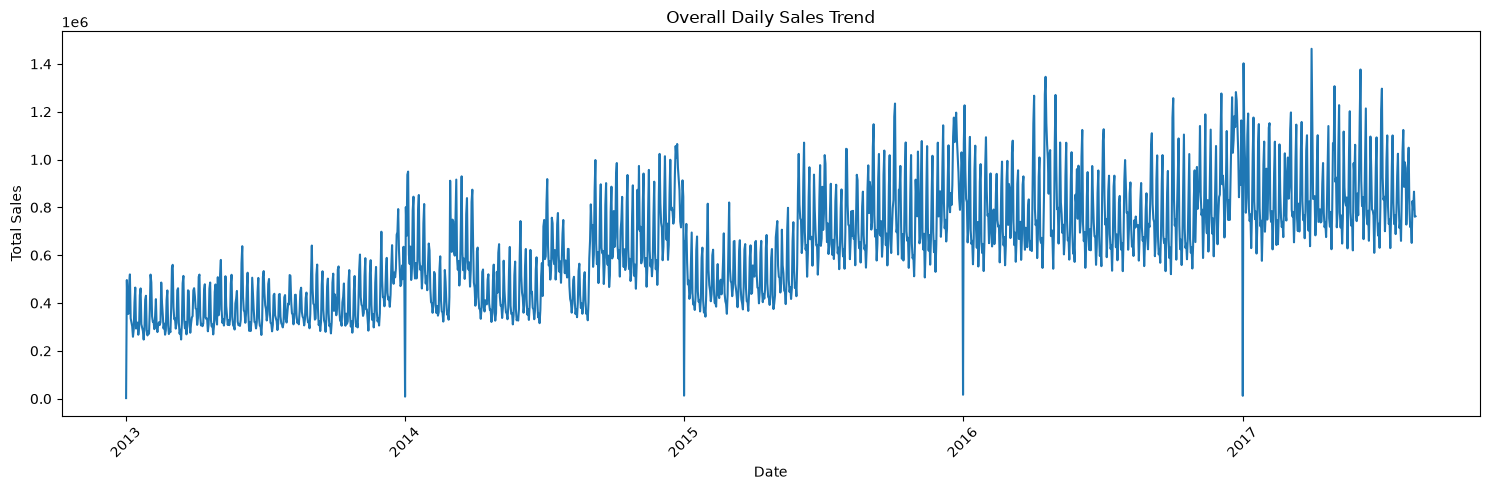

In [16]:
# Overall demand trend.
plt.figure(figsize=(15, 5))
plt.plot(daily["date"], daily["sales"])
plt.title("Overall Daily Sales Trend")
plt.xlabel("Date")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


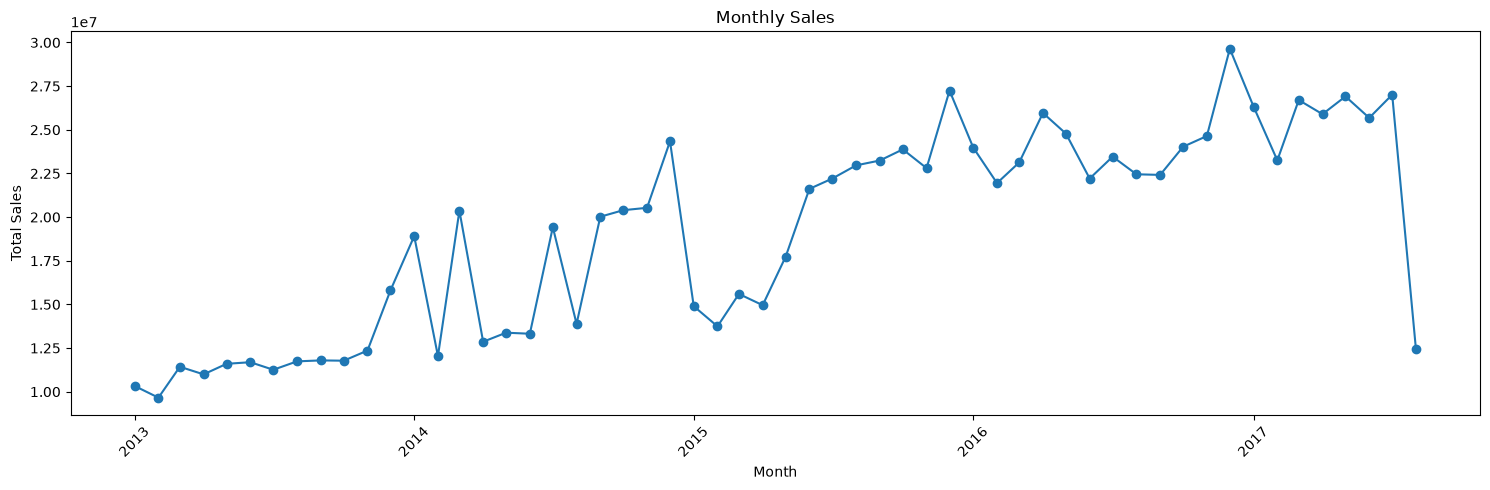

In [17]:
# Monthly trend.
monthly = (
    daily.set_index("date")["sales"]
    .resample("MS")
    .sum()
)

plt.figure(figsize=(15, 5))
plt.plot(monthly.index, monthly.values, marker="o")
plt.title("Monthly Sales")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [18]:
# Day-of-week seasonality.
analysis = train.copy()
analysis["day_of_week"] = analysis["date"].dt.dayofweek
analysis["month"] = analysis["date"].dt.month

dow = analysis.groupby("day_of_week")["sales"].mean()
month = analysis.groupby("month")["sales"].mean()

print("Average sales by day of week:")
display(dow.to_frame("average_sales"))

print("Average sales by month:")
display(month.to_frame("average_sales"))


Average sales by day of week:


,average_sales
day_of_week,
0,346.54
1,319.82
2,332.91
3,283.54
4,325.24
5,433.34
6,463.09


Average sales by month:


,average_sales
month,
1,341.92
2,320.93
3,352.01
4,339.20
5,341.77
6,353.60
7,374.22
8,336.99
9,362.30


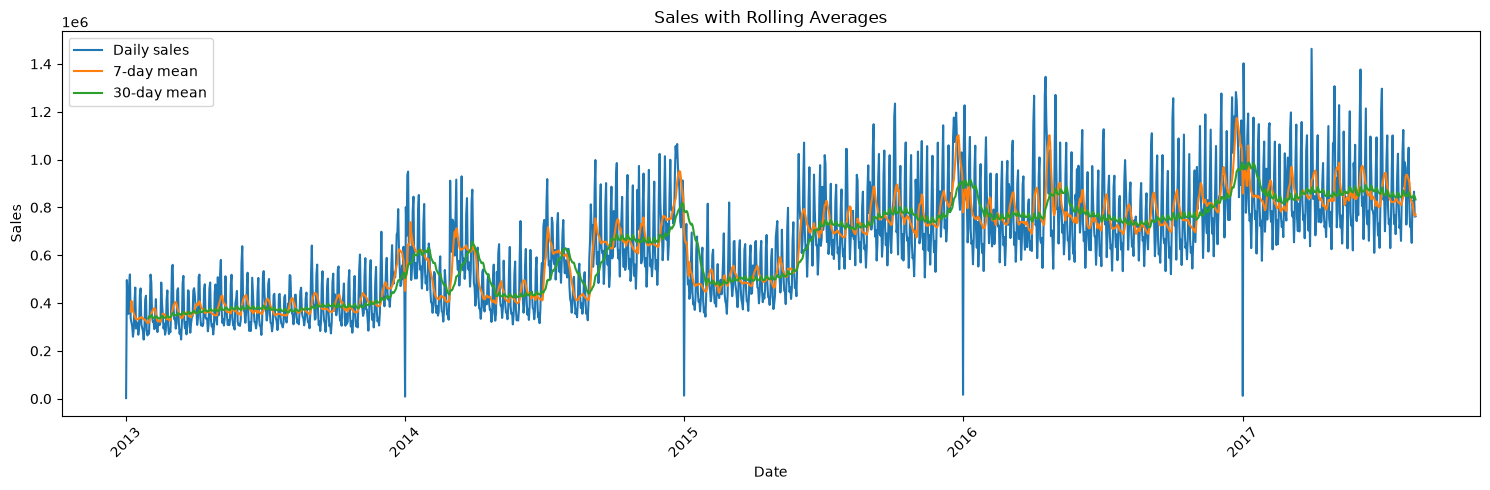

In [19]:
# Rolling mean and rolling standard deviation.
daily_analysis = daily.copy()
daily_analysis["rolling_mean_7"] = daily_analysis["sales"].rolling(7).mean()
daily_analysis["rolling_std_7"] = daily_analysis["sales"].rolling(7).std()
daily_analysis["rolling_mean_30"] = daily_analysis["sales"].rolling(30).mean()

plt.figure(figsize=(15, 5))
plt.plot(daily_analysis["date"], daily_analysis["sales"], label="Daily sales")
plt.plot(daily_analysis["date"], daily_analysis["rolling_mean_7"], label="7-day mean")
plt.plot(daily_analysis["date"], daily_analysis["rolling_mean_30"], label="30-day mean")
plt.title("Sales with Rolling Averages")
plt.xlabel("Date")
plt.ylabel("Sales")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [20]:
# Compare sales with lagged versions.
for lag in [1, 7, 14, 28, 30, 60, 90]:
    daily_analysis[f"lag_{lag}"] = daily_analysis["sales"].shift(lag)

correlations = {}
for lag in [1, 7, 14, 28, 30, 60, 90]:
    correlations[lag] = daily_analysis["sales"].corr(
        daily_analysis[f"lag_{lag}"]
    )

lag_correlation = (
    pd.Series(correlations, name="correlation")
    .rename_axis("lag_days")
    .sort_values(ascending=False)
)

display(lag_correlation.to_frame())


,correlation
lag_days,
7,0.83
14,0.82
28,0.78
1,0.77
90,0.62
30,0.49
60,0.44


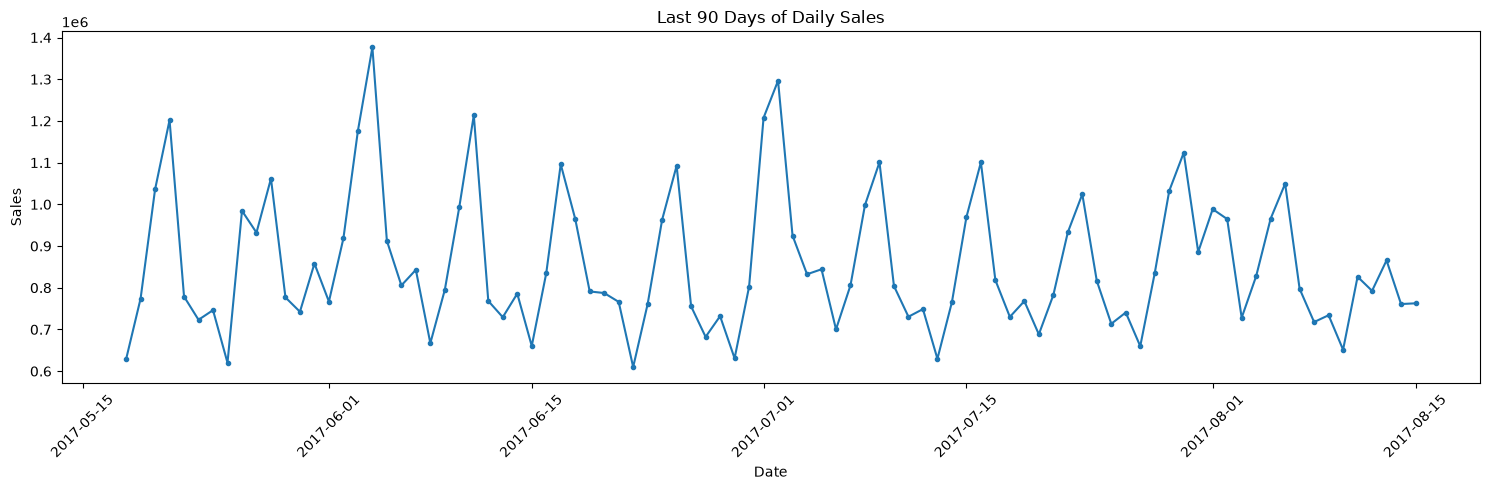

In [21]:
# Recent period: useful for seeing current behaviour.
recent = daily_analysis.tail(90)

plt.figure(figsize=(15, 5))
plt.plot(recent["date"], recent["sales"], marker=".")
plt.title("Last 90 Days of Daily Sales")
plt.xlabel("Date")
plt.ylabel("Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


## Time-series conclusion

The important modelling decision is:

**Past → Train | Recent → Validation | Future → Test**

We will not randomly shuffle these observations because that would allow future patterns to influence the past.
